In [1]:
#!/usr/bin/env python3

# %pip install numpy matplotlib seaborn scikit-learn pillow tqdm pandas
# %pip install torch torchvision # --index-url https://download.pytorch.org/whl/cu126

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights


Проверка устройства и ускорителя

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


### Подготовка данных

Правила подготовки датасетов

Для всех картинок:
- преобразуем размеры к $224 \times 224$ (для ResNet18)
- нормализуем цветовые каналы (для ResNet18)
- преобразуем картинки в тензоры

Для тренировочно-валидационного датасета:
- случайно зеркалим картинки
- случайно поворачиваем картинки на $\pm10^\circ$

Разделяем основной датасет на тренировочный и валидационный

In [4]:
dataset_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.224, 0.229],
        std=[0.229, 0.224, 0.225]
    )
])

Загрузка и подготовка датасетов

In [5]:
data_dir = "./data"

dataset = datasets.OxfordIIITPet(
    root=data_dir,
    split="trainval",
    target_types="category",
    download=True,
    transform=dataset_transform
)

test_dataset = datasets.OxfordIIITPet(
    root=data_dir,
    split="test",
    target_types="category",
    download=True,
    transform=test_dataset_transform
)
print("Train/Val:", len(dataset))
print("Test:", len(test_dataset))


Train/Val: 3680
Test: 3669


In [6]:
class_names = dataset.classes
print("Количество классов:", len(class_names))
print("Классы:\n" + ", ".join([f"{i} -> {name}" for i, name in enumerate(class_names)]))

Количество классов: 37
Классы:
0 -> Abyssinian, 1 -> American Bulldog, 2 -> American Pit Bull Terrier, 3 -> Basset Hound, 4 -> Beagle, 5 -> Bengal, 6 -> Birman, 7 -> Bombay, 8 -> Boxer, 9 -> British Shorthair, 10 -> Chihuahua, 11 -> Egyptian Mau, 12 -> English Cocker Spaniel, 13 -> English Setter, 14 -> German Shorthaired, 15 -> Great Pyrenees, 16 -> Havanese, 17 -> Japanese Chin, 18 -> Keeshond, 19 -> Leonberger, 20 -> Maine Coon, 21 -> Miniature Pinscher, 22 -> Newfoundland, 23 -> Persian, 24 -> Pomeranian, 25 -> Pug, 26 -> Ragdoll, 27 -> Russian Blue, 28 -> Saint Bernard, 29 -> Samoyed, 30 -> Scottish Terrier, 31 -> Shiba Inu, 32 -> Siamese, 33 -> Sphynx, 34 -> Staffordshire Bull Terrier, 35 -> Wheaten Terrier, 36 -> Yorkshire Terrier


Разделяем основной датасет на тренировочный и валидационный 80/20

In [7]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2944
Validation: 736
Test: 3669


Настраиваем пакетную передачу данных

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

images, labels = next(iter(train_loader))

print(f"""Images:
\tbatch_size={images.shape[0]}
\tcolor_channels={images.shape[1]}
\twidth={images.shape[2]}
\theight={images.shape[3]}
Labels:
\tbatch_size={images.shape[0]}""")

Images:
	batch_size=32
	color_channels=3
	width=224
	height=224
Labels:
	batch_size=32


### ResNet18 — Feature Extraction

In [9]:
weights = ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Замораживаем все параметры предобученной сети
for param in model.parameters():
    param.requires_grad = False

# Заменяем последний классификатор на 37 классов
model.fc = nn.Linear(model.fc.in_features, len(class_names))

# Переносим модель на GPU
model = model.to(device)

Обучение (Feature Extraction)

In [10]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=1e-3
)

num_epochs = 10

best_val_acc = 0.0
best_model_state = None

# История обучения
train_losses = []
train_accs = []
val_accs = []

print(f"Starting training for {num_epochs} epochs")

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total

    # Сохраняем значения
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = model.state_dict().copy()

print(f"\nBest Validation Accuracy: {best_val_acc:.4f}")

Starting training for 10 epochs
Epoch 1/10 | Train Loss: 2.2410 | Train Acc: 0.4789 | Val Acc: 0.7527
Epoch 2/10 | Train Loss: 0.9483 | Train Acc: 0.8084 | Val Acc: 0.8261
Epoch 3/10 | Train Loss: 0.6628 | Train Acc: 0.8550 | Val Acc: 0.8383
Epoch 4/10 | Train Loss: 0.5254 | Train Acc: 0.8845 | Val Acc: 0.8397
Epoch 5/10 | Train Loss: 0.4678 | Train Acc: 0.8855 | Val Acc: 0.8519
Epoch 6/10 | Train Loss: 0.3983 | Train Acc: 0.9042 | Val Acc: 0.8560
Epoch 7/10 | Train Loss: 0.3581 | Train Acc: 0.9147 | Val Acc: 0.8750
Epoch 8/10 | Train Loss: 0.3295 | Train Acc: 0.9181 | Val Acc: 0.8573
Epoch 9/10 | Train Loss: 0.2990 | Train Acc: 0.9310 | Val Acc: 0.8573
Epoch 10/10 | Train Loss: 0.2843 | Train Acc: 0.9283 | Val Acc: 0.8682

Best Validation Accuracy: 0.8750


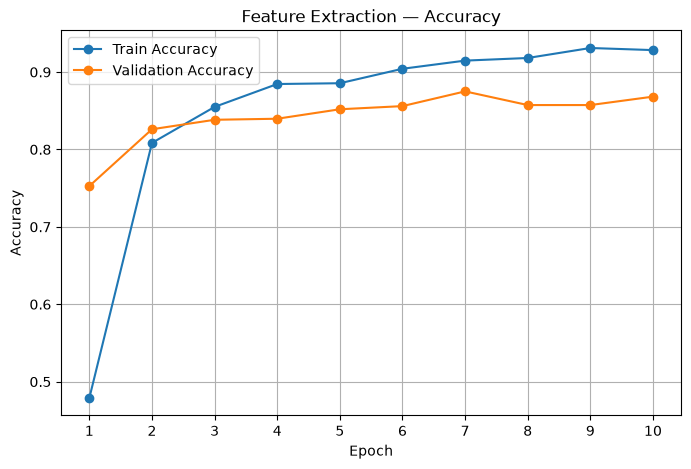

In [11]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accs, marker="o", label="Train Accuracy")
plt.plot(epochs, val_accs, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Feature Extraction — Accuracy")
plt.xticks(list(epochs))
plt.grid(True)
plt.legend()
plt.show()

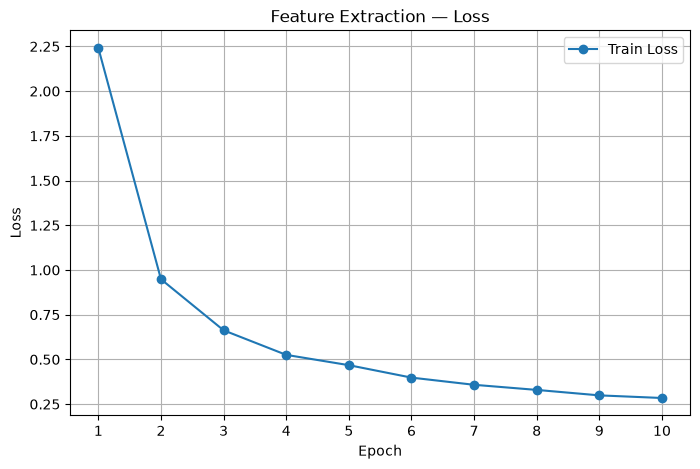

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Train Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Feature Extraction — Loss")
plt.xticks(list(epochs))
plt.grid(True)
plt.legend()
plt.show()

Оценка на тестовой выборке (Feature Extraction)

In [13]:
model.load_state_dict(best_model_state)
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

Метрики (Feature Extraction)

In [14]:
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)
test_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)
test_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1-score:  {test_f1:.4f}")

Test Accuracy:  0.7225
Test Precision: 0.7595
Test Recall:    0.7222
Test F1-score:  0.7210


Confusion Matrix (Feature Extraction)

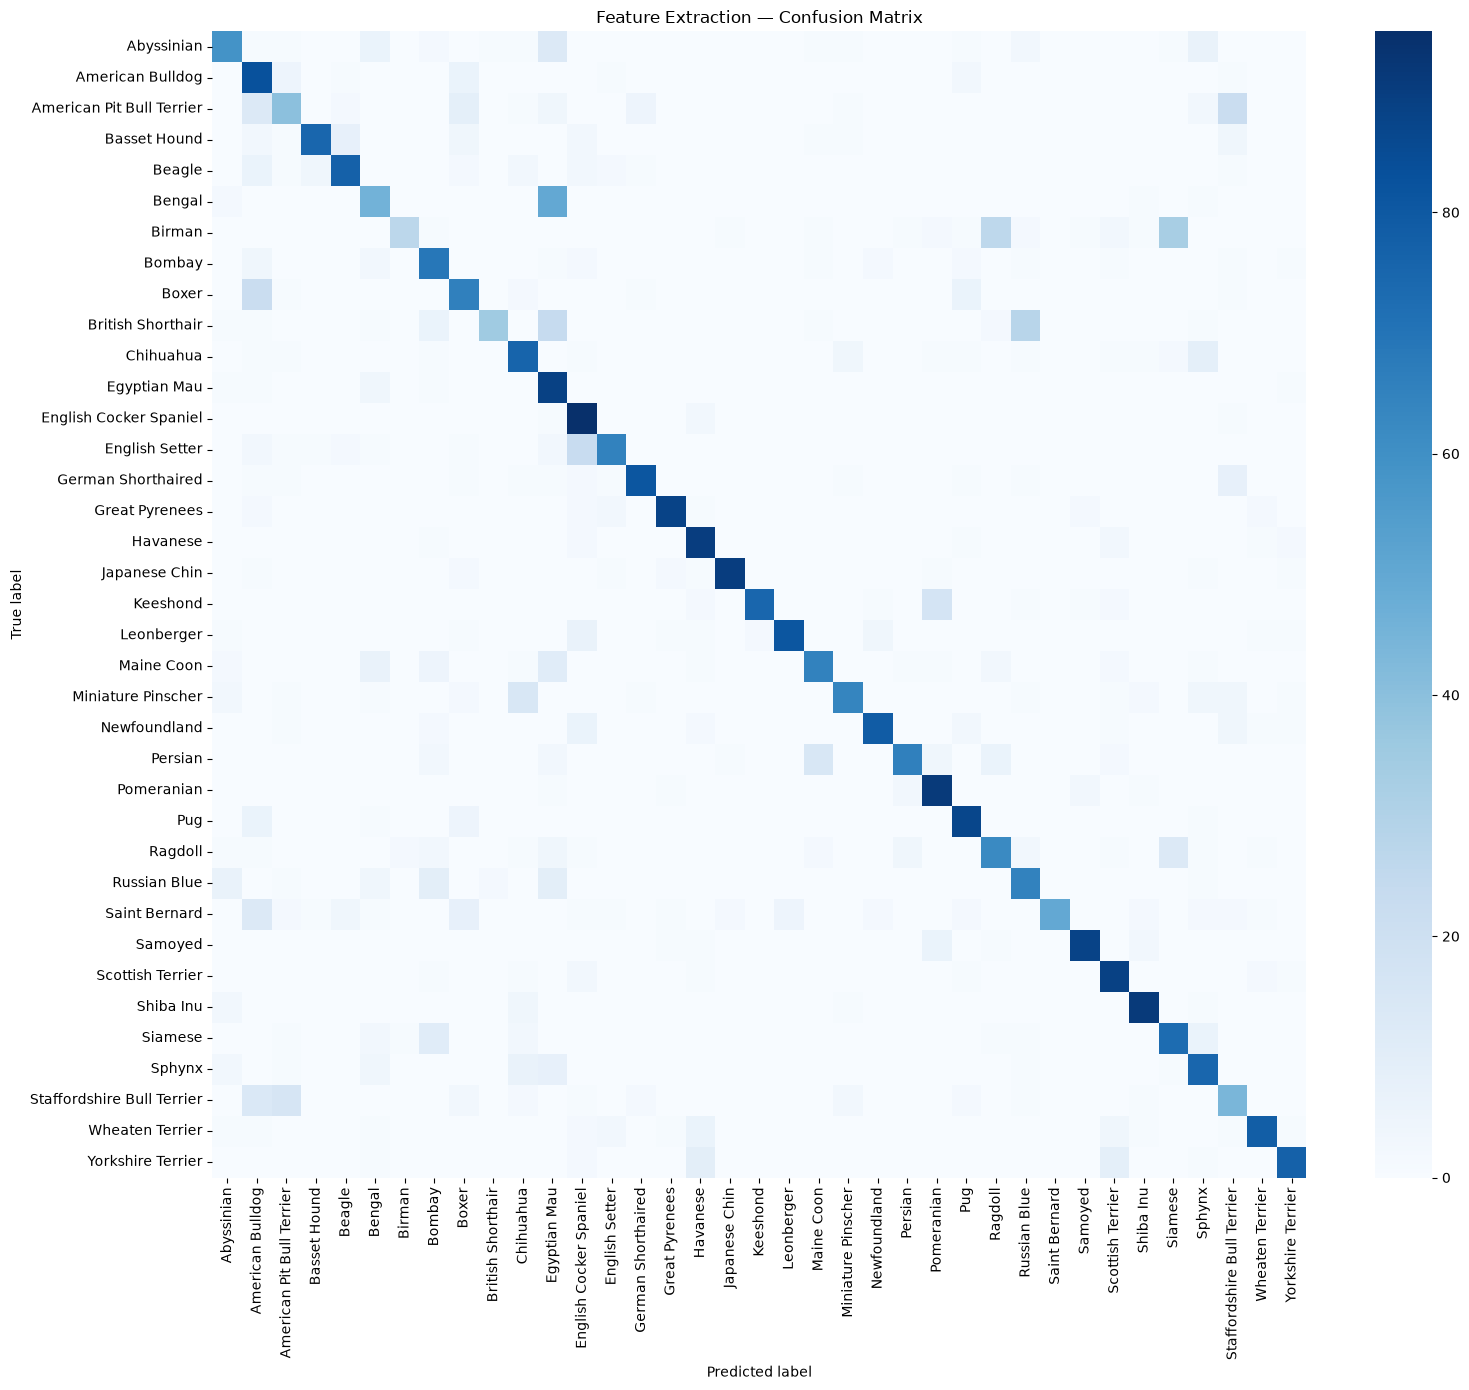

In [15]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Feature Extraction — Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### ResNet18 — Fine-tuning

In [16]:
weights = ResNet18_Weights.DEFAULT
model_ft = models.resnet18(weights=weights)

# Сначала замораживаем всю предобученную сеть
for param in model_ft.parameters():
    param.requires_grad = False

# Размораживаем последний residual block — layer4
for param in model_ft.layer4.parameters():
    param.requires_grad = True

# Заменяем классификатор на 37 классов
model_ft.fc = nn.Linear(
    model_ft.fc.in_features,
    len(class_names)
)

# Переносим модель на GPU
model_ft = model_ft.to(device)

Проверяем обучаемые параметры (Fine-tuning)

In [17]:
print("Trainable parameters:")

for name, param in model_ft.named_parameters():
    if param.requires_grad:
        print(name)

Trainable parameters:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


Обучение (Fine-tuning)

In [18]:
criterion_ft = nn.CrossEntropyLoss()

optimizer_ft = optim.Adam(
    filter(lambda p: p.requires_grad, model_ft.parameters()),
    lr=1e-4
)

num_epochs_ft = 10

best_val_acc_ft = 0.0
best_model_state_ft = None

# История обучения
train_losses_ft = []
train_accs_ft = []
val_accs_ft = []

print(f"Starting Fine-tuning for {num_epochs_ft} epochs")

for epoch in range(num_epochs_ft):
    # Training
    model_ft.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_ft.zero_grad()

        outputs = model_ft(images)
        loss = criterion_ft(outputs, labels)

        loss.backward()
        optimizer_ft.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model_ft.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_ft(images)
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total

    # Сохраняем историю
    train_losses_ft.append(train_loss)
    train_accs_ft.append(train_acc)
    val_accs_ft.append(val_acc)

    print(
        f"Epoch {epoch + 1}/{num_epochs_ft} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Сохраняем лучшую модель
    if val_acc > best_val_acc_ft:
        best_val_acc_ft = val_acc
        best_model_state_ft = {
            key: value.cpu().clone()
            for key, value in model_ft.state_dict().items()
        }

print(f"\nBest Validation Accuracy: {best_val_acc_ft:.4f}")

Starting Fine-tuning for 10 epochs
Epoch 1/10 | Train Loss: 2.0095 | Train Acc: 0.5622 | Val Acc: 0.8179
Epoch 2/10 | Train Loss: 0.7102 | Train Acc: 0.8815 | Val Acc: 0.8519
Epoch 3/10 | Train Loss: 0.4009 | Train Acc: 0.9344 | Val Acc: 0.8736
Epoch 4/10 | Train Loss: 0.2603 | Train Acc: 0.9630 | Val Acc: 0.8859
Epoch 5/10 | Train Loss: 0.1667 | Train Acc: 0.9772 | Val Acc: 0.9008
Epoch 6/10 | Train Loss: 0.1135 | Train Acc: 0.9905 | Val Acc: 0.8845
Epoch 7/10 | Train Loss: 0.0813 | Train Acc: 0.9935 | Val Acc: 0.8872
Epoch 8/10 | Train Loss: 0.0584 | Train Acc: 0.9963 | Val Acc: 0.8899
Epoch 9/10 | Train Loss: 0.0435 | Train Acc: 0.9980 | Val Acc: 0.9049
Epoch 10/10 | Train Loss: 0.0335 | Train Acc: 0.9993 | Val Acc: 0.8967

Best Validation Accuracy: 0.9049


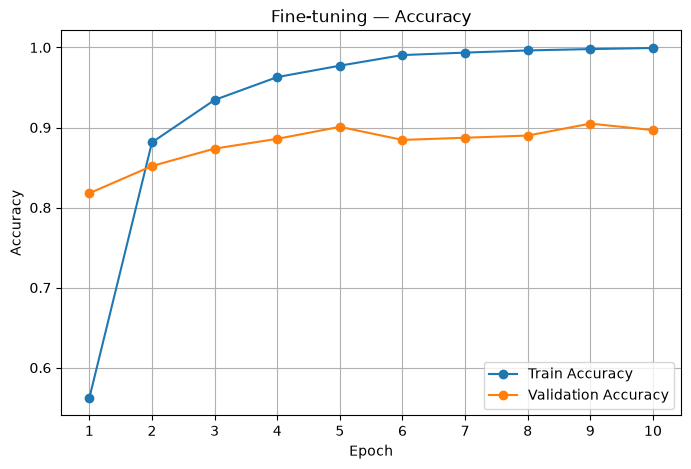

In [19]:
epochs_ft = range(1, num_epochs_ft + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_ft,
    train_accs_ft,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs_ft,
    val_accs_ft,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-tuning — Accuracy")
plt.xticks(list(epochs_ft))
plt.grid(True)
plt.legend()

plt.show()

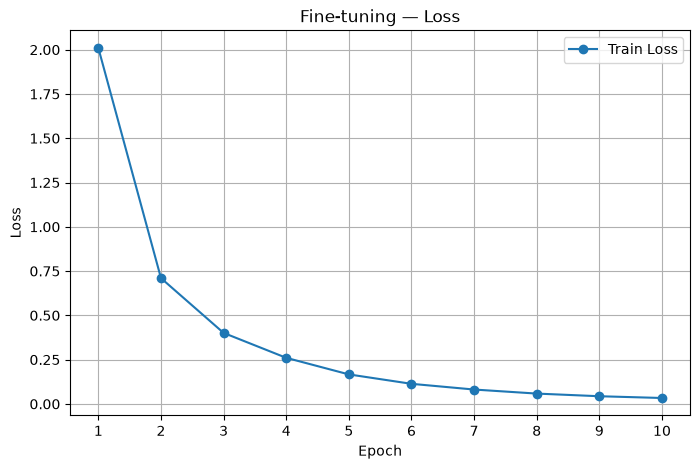

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_ft,
    train_losses_ft,
    marker="o",
    label="Train Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-tuning — Loss")
plt.xticks(list(epochs_ft))
plt.grid(True)
plt.legend()

plt.show()

Оценка на тестовой выборке (Fine-tuning)

In [21]:
model_ft.load_state_dict(best_model_state_ft)
model_ft = model_ft.to(device)
model_ft.eval()

all_labels_ft = []
all_predictions_ft = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_ft(images)
        _, predictions = torch.max(outputs, 1)

        all_labels_ft.extend(labels.cpu().numpy())
        all_predictions_ft.extend(predictions.cpu().numpy())

print("Test predictions completed.")

Test predictions completed.


Метрики (Fine-tuning)

In [22]:
test_accuracy_ft = accuracy_score(
    all_labels_ft,
    all_predictions_ft
)
test_precision_ft = precision_score(
    all_labels_ft,
    all_predictions_ft,
    average="macro",
    zero_division=0
)
test_recall_ft = recall_score(
    all_labels_ft,
    all_predictions_ft,
    average="macro",
    zero_division=0
)
test_f1_ft = f1_score(
    all_labels_ft,
    all_predictions_ft,
    average="macro",
    zero_division=0
)

print(f"Fine-tuning Test Accuracy:  {test_accuracy_ft:.4f}")
print(f"Fine-tuning Test Precision: {test_precision_ft:.4f}")
print(f"Fine-tuning Test Recall:    {test_recall_ft:.4f}")
print(f"Fine-tuning Test F1-score:  {test_f1_ft:.4f}")

Fine-tuning Test Accuracy:  0.7860
Fine-tuning Test Precision: 0.8044
Fine-tuning Test Recall:    0.7859
Fine-tuning Test F1-score:  0.7842


Confusion Matrix (Fine-tuning)

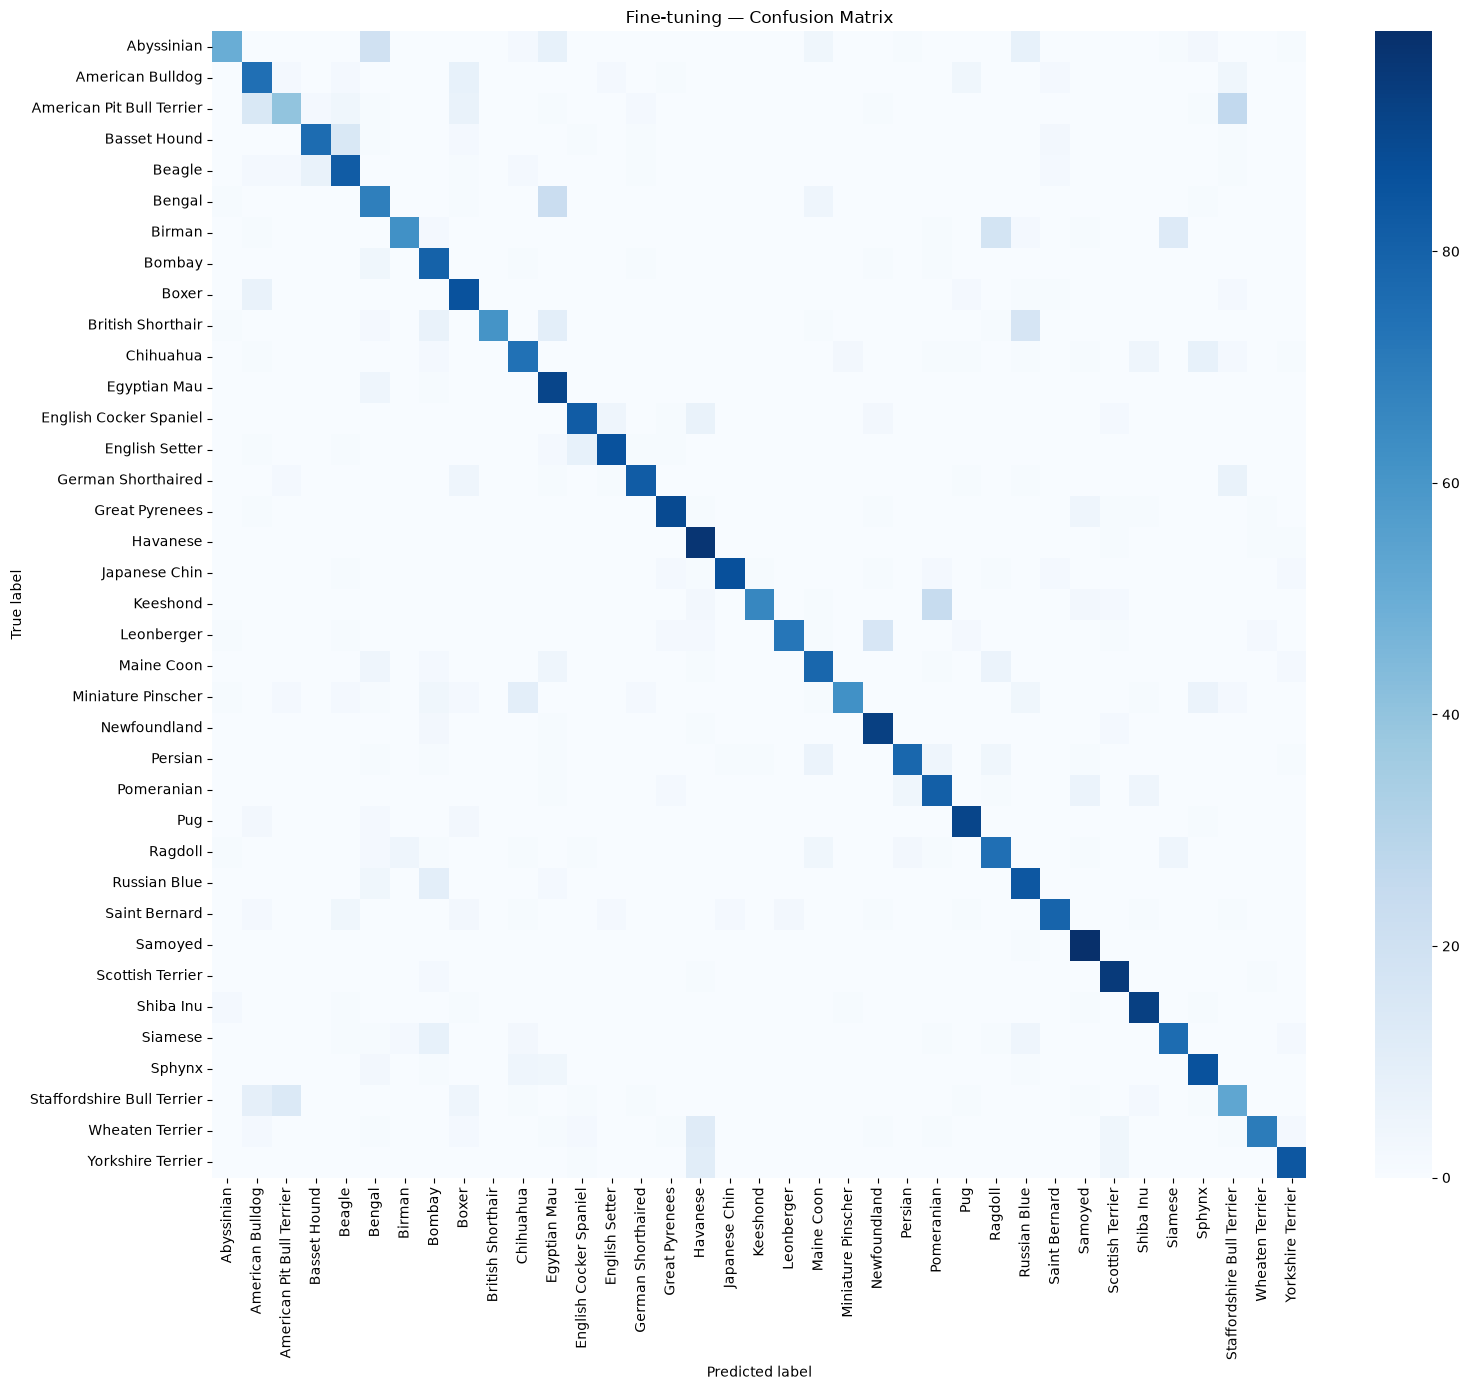

In [23]:
cm_ft = confusion_matrix(
    all_labels_ft,
    all_predictions_ft
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_ft,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Fine-tuning — Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Сравнение

In [24]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Feature Extraction": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ],
    "Fine-tuning": [
        test_accuracy_ft,
        test_precision_ft,
        test_recall_ft,
        test_f1_ft
    ]
})

comparison["Improvement"] = (
    comparison["Fine-tuning"] -
    comparison["Feature Extraction"]
)

comparison_display = comparison.copy()

for col in ["Feature Extraction", "Fine-tuning"]:
    comparison_display[col] = (
        comparison_display[col] * 100
    ).round(2).astype(str) + "%"

comparison_display["Improvement"] = (
    comparison["Improvement"] * 100
).round(2).astype(str) + " п.п."

comparison_display

,Metric,Feature Extraction,Fine-tuning,Improvement
0,Accuracy,72.25%,78.6%,6.35 п.п.
1,Precision,75.95%,80.44%,4.49 п.п.
2,Recall,72.22%,78.59%,6.37 п.п.
3,F1-score,72.1%,78.42%,6.32 п.п.


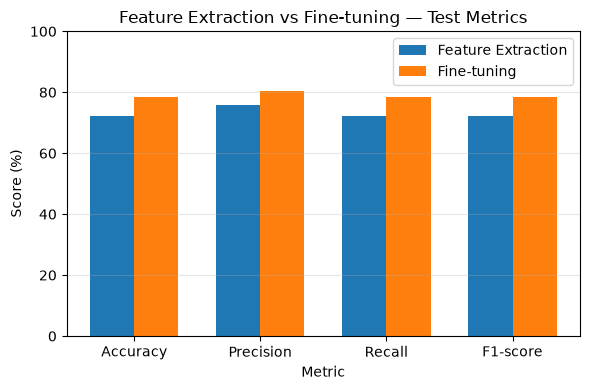

In [25]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

fe_values = [
    test_accuracy,
    test_precision,
    test_recall,
    test_f1
]

ft_values = [
    test_accuracy_ft,
    test_precision_ft,
    test_recall_ft,
    test_f1_ft
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(6, 4))

plt.bar(
    x - width / 2,
    np.array(fe_values) * 100,
    width,
    label="Feature Extraction"
)

plt.bar(
    x + width / 2,
    np.array(ft_values) * 100,
    width,
    label="Fine-tuning"
)

plt.ylabel("Score (%)")
plt.xlabel("Metric")
plt.title("Feature Extraction vs Fine-tuning — Test Metrics")

plt.xticks(x, metrics)
plt.ylim(0, 100)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

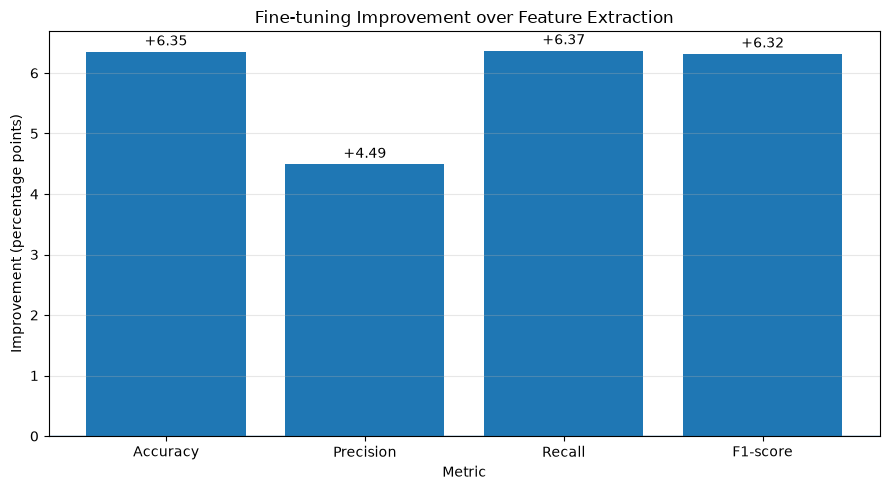

In [26]:
improvements = (
    np.array(ft_values) -
    np.array(fe_values)
) * 100

plt.figure(figsize=(9, 5))

bars = plt.bar(metrics, improvements)

plt.axhline(0, linewidth=1)

plt.ylabel("Improvement (percentage points)")
plt.xlabel("Metric")
plt.title("Fine-tuning Improvement over Feature Extraction")

plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, improvements):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"+{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Визульные примеры выполнения кода

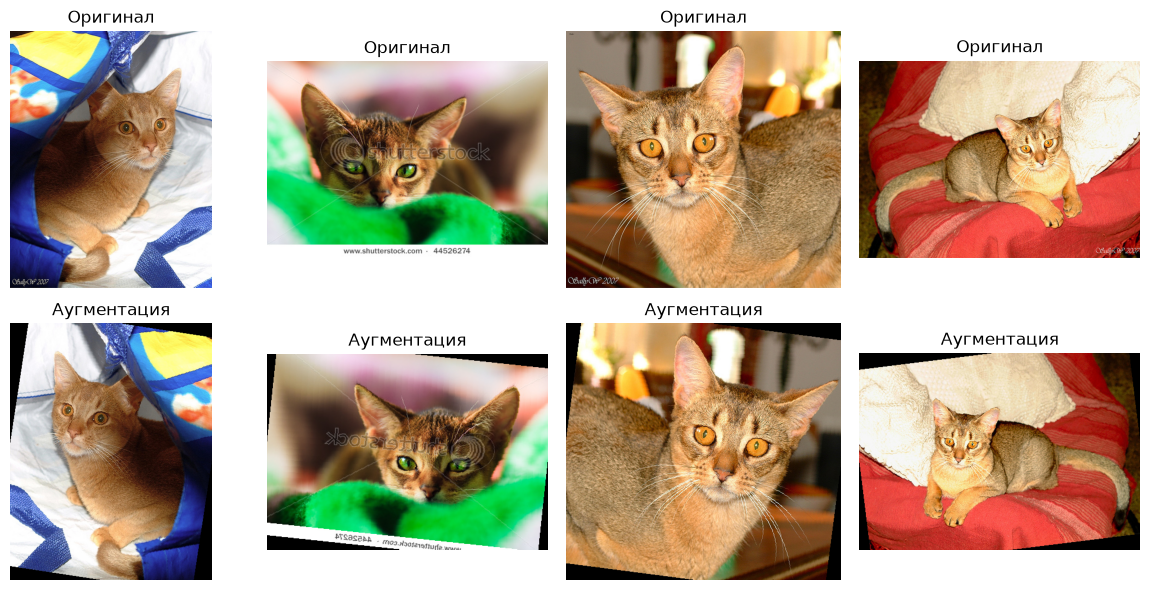

In [ ]:
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Загружаем датасет без преобразований
dataset_vis = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=False
)

# Аугментации
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.RandomRotation(10)
])

# Выбираем 4 изображения
indices = [0, 1, 2, 3]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, idx in enumerate(indices):
    image, label = dataset_vis[idx]

    # Верхний ряд — оригинальные изображения
    axes[0, i].imshow(image)
    axes[0, i].set_title("Оригинал")
    axes[0, i].axis("off")

    # Нижний ряд — аугментированные изображения
    augmented = augmentation(image)
    axes[1, i].imshow(augmented)
    axes[1, i].set_title("Аугментация")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()